# 02 · Línea base con LightGBM (y comparación de clases)

**Etapa 2 del plan** (`fichas/etapa_2_linea_base.md`). Se adelanta la etapa 3.

**Qué mide:** cuánta plata gana un LightGBM **sin mejoras**, con variables crudas y hiperparámetros ya probados por la cátedra. Lo mide en dos backtests que imitan la competencia: dos meses de distancia entre el entrenamiento y el mes a predecir.

| Prueba | Entrena con | Predice |
|---|---|---|
| **A** | `202103`–`202104` | `202106` |
| **B** | `202103` | `202105` |

**Qué compara** (4 configuraciones):

| | `BAJA+2` sola | `BAJA+1` + `BAJA+2` |
|---|---|---|
| **`z601`** (lunes) | `z601_baja2` | `z601_bajas` |
| **`z470`** (jueves) | `z470_baja2` | `z470_bajas` |

**La ganancia siempre se mide con `BAJA+2` como único acierto**, aunque el modelo se entrene con las dos bajas. El corte es por **cantidad de envíos (N)**, en el máximo de la curva de ganancia suavizada (media móvil de 501, `z0607`).

**No** limpia variables, **no** arma variables nuevas y **no** optimiza: eso viene después. El primer submit sale del `03_entrega.ipynb`.

## 1. Parámetros

**`MODO_RAPIDO = True`** corre **una sola semilla** por configuración y prueba: 8 modelos. Sirve para medir el tiempo real antes de la corrida completa (ficha: "conviene correr primero una sola semilla").

Con `False` corre las 10 semillas: 80 modelos. Cada modelo se guarda apenas termina; si se corta la corrida, al volver a correr **retoma** desde donde quedó.

In [9]:
from itertools import product
from pathlib import Path
import json
import time
import warnings

import duckdb
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

warnings.filterwarnings('ignore', message='.*ChainedAssignmentError.*')  # falso positivo pandas 2.2 + Py 3.14

# --- Parámetros -------------------------------------------------------------
MODO_RAPIDO = False          # True: 1 semilla (medir tiempos) · False: corrida completa

BASE_PARQUET = Path('../data/competencia_01_base.parquet')
EXP = Path('../exp/02_linea_base')
CURVAS = EXP / 'curvas'      # una curva por (configuración, prueba, semilla)

SEMILLA_PRIMIGENIA = 979201
N_SEMILLAS_TOTAL = 20        # el 03 usa las 20 para el modelo final
N_SEMILLAS_BACKTEST = 10

GANANCIA_ACIERTO = 1_072_500
COSTO_ESTIMULO = 27_500
VENTANA_SUAVIZADO = 501      # media móvil centrada, como z0607
LARGO_CURVA = 25_000         # se guarda la curva hasta 25.000 envíos (el bot acepta 8.000–15.000)
CORTES = list(range(8_000, 15_001, 500))

PRUEBAS = {
    'A': {'train': [202103, 202104], 'test': 202106},
    'B': {'train': [202103], 'test': 202105},
}

# Clases positivas de cada esquema (la ganancia SIEMPRE cuenta solo BAJA+2)
CLASES = {
    'baja2': ['BAJA+2'],
    'bajas': ['BAJA+1', 'BAJA+2'],
}

# Hiperparámetros de la cátedra, tal cual sus notebooks
HIPERPARAMETROS = {
    # z601 (lunes): model_params + num_boost_round=250. Su bagging_fraction NO tiene efecto
    # porque no fija bagging_freq; se deja así para reproducir el notebook de clase.
    'z601': dict(objective='binary', boosting='gbdt', first_metric_only=True,
                 boost_from_average=True, feature_pre_filter=False, max_bin=31,
                 num_leaves=16, learning_rate=0.019868, min_data_in_leaf=816,
                 feature_fraction=0.277155, bagging_fraction=0.634130,
                 num_iterations=250, verbose=-1),
    # z470 (jueves): PARAM$lgb de "LightGBM, una corrida"
    'z470': dict(objective='binary', boosting='gbdt', max_bin=31,
                 num_leaves=8, learning_rate=0.027, min_data_in_leaf=76,
                 feature_fraction=0.8, num_iterations=1000, verbose=-1),
}

VARIABLES_EXCLUIDAS = ['clase_ternaria', 'foto_mes']   # decisión de la etapa 2
# -----------------------------------------------------------------------------

EXP.mkdir(parents=True, exist_ok=True)
CURVAS.mkdir(parents=True, exist_ok=True)
assert BASE_PARQUET.exists(), f'Falta el dataset base: correr 01_pipeline_base ({BASE_PARQUET.resolve()})'

# Fuente única de la configuración: el 03_entrega lee este archivo en vez de copiar los parámetros
(EXP / 'configuraciones.json').write_text(json.dumps(
    {'hiperparametros': HIPERPARAMETROS, 'clases': CLASES, 'variables_excluidas': VARIABLES_EXCLUIDAS,
     'pruebas': PRUEBAS, 'cortes': CORTES, 'ventana_suavizado': VENTANA_SUAVIZADO,
     'ganancia_acierto': GANANCIA_ACIERTO, 'costo_estimulo': COSTO_ESTIMULO}, indent=2))

1334

## 2. Semillas

Salen de la semilla primigenia, como en `z0201`:
1. se arman todos los primos de 6 dígitos;
2. se sortean 20 sin reemplazo con `numpy.random.default_rng(979201)`.

Siempre dan **las mismas y en el mismo orden**. Las primeras 10 son las de los backtests; las 20, las del modelo final (`03`).

In [10]:
def primos_6_digitos():
    criba = np.ones(1_000_000, dtype=bool)
    criba[:2] = False
    for i in range(2, 1_001):
        if criba[i]:
            criba[i * i::i] = False
    return np.flatnonzero(criba[100_000:]) + 100_000


SEMILLAS = np.random.default_rng(SEMILLA_PRIMIGENIA).choice(
    primos_6_digitos(), size=N_SEMILLAS_TOTAL, replace=False).tolist()
SEMILLAS_BACKTEST = SEMILLAS[:N_SEMILLAS_BACKTEST]
SEMILLAS_A_USAR = SEMILLAS_BACKTEST[:1] if MODO_RAPIDO else SEMILLAS_BACKTEST

(EXP / 'semillas.json').write_text(json.dumps(
    {'semilla_primigenia': SEMILLA_PRIMIGENIA, 'semillas': SEMILLAS}, indent=2))
print('Semillas:', SEMILLAS)
print(f'En esta corrida: {len(SEMILLAS_A_USAR)} por configuración y prueba')

Semillas: [294103, 342929, 161093, 677561, 431077, 330679, 511579, 312773, 118147, 567529, 859783, 505619, 909541, 646669, 902723, 138629, 865801, 316957, 254447, 994321]
En esta corrida: 10 por configuración y prueba


## 3. Datos

Se lee el dataset base completo (~0,6 GB en memoria con `float32`). Las variables son todas menos `clase_ternaria` y `foto_mes`.
- **`foto_mes`:** con varios meses de entrenamiento, el modelo puede aprender "el mes", y en `202108` el valor queda fuera de rango.
- **`numero_de_cliente`:** queda como variable, como en los notebooks de la cátedra.

**Filas de entrenamiento:** solo las de los meses de la prueba **que tienen clase**. `202107` no se usa nunca para entrenar.

In [11]:
t0 = time.time()
# Se lee con DuckDB (pandas necesitaría pyarrow, que no está instalado)
df = duckdb.sql(f"select * from read_parquet('{BASE_PARQUET.as_posix()}')").df()
VARIABLES = [c for c in df.columns if c not in VARIABLES_EXCLUIDAS]
print(f'{len(df):,} filas · {len(VARIABLES)} variables · {time.time() - t0:.0f} s')
assert 'clase_ternaria' not in VARIABLES and 'foto_mes' not in VARIABLES
assert df['numero_de_cliente'].dtype == 'int64'
assert df[VARIABLES[1:]].dtypes.eq('float32').all(), 'las variables tienen que venir en float32'


def particion(prueba):
    """Índices de entrenamiento y de prueba de un backtest."""
    meses = PRUEBAS[prueba]
    es_train = df['foto_mes'].isin(meses['train']) & df['clase_ternaria'].notna()
    es_test = df['foto_mes'] == meses['test']
    assert not (es_train & es_test).any()
    assert df.loc[es_train, 'foto_mes'].max() < meses['test'] - 1, 'falta la distancia de 2 meses'
    return np.flatnonzero(es_train), np.flatnonzero(es_test)


# Control de la ficha (#1 y #2): meses y positivos de entrenamiento
for prueba in PRUEBAS:
    i_train, i_test = particion(prueba)
    clases_train = df['clase_ternaria'].iloc[i_train]
    print(f"{prueba}: train {sorted(int(m) for m in df['foto_mes'].iloc[i_train].unique())} ({len(i_train):,} filas) · "
          f"test {PRUEBAS[prueba]['test']} ({len(i_test):,}) · "
          f"BAJA+2 en train: {(clases_train == 'BAJA+2').sum():,} · "
          f"las dos bajas: {clases_train.isin(CLASES['bajas']).sum():,}")

983,061 filas · 153 variables · 1 s
A: train [202103, 202104] (326,184 filas) · test 202106 (164,114) · BAJA+2 en train: 2,099 · las dos bajas: 4,082
B: train [202103] (162,900 filas) · test 202105 (163,768) · BAJA+2 en train: 960 · las dos bajas: 1,979


## 4. Funciones de ganancia

- **Curva de ganancia:**
  1. se ordena a los clientes del mes de prueba por probabilidad descendente;
  2. se acumula +1.072.500 si es `BAJA+2` y −27.500 si no lo es.

  El valor en la posición N es la ganancia de mandar N estímulos.
- **Meseta:** la curva se suaviza con una media móvil centrada de 501 posiciones y se toma su máximo. N es la posición del máximo; es "elegir N en la meseta" y no en un pico con suerte (`z0607`, CLAUDE.md §3).
- **Varias semillas:** se promedian las curvas posición por posición y después se suaviza. El desvío entre semillas sale de la meseta de cada semilla por separado.

In [12]:
def curva_ganancia(prob, es_baja2, largo=LARGO_CURVA):
    orden = np.argsort(-prob, kind='stable')
    ganancia = np.where(es_baja2[orden], GANANCIA_ACIERTO, -COSTO_ESTIMULO)
    return np.cumsum(ganancia)[:largo].astype(np.float64)


def suavizar(curva, ventana=VENTANA_SUAVIZADO):
    return pd.Series(curva).rolling(ventana, center=True, min_periods=ventana).mean().to_numpy()


def meseta(curva):
    """(N, ganancia) en el máximo de la curva suavizada."""
    s = suavizar(curva)
    i = int(np.nanargmax(s))
    return i + 1, float(s[i])

## 5. Backtests

Para cada configuración, prueba y semilla:
1. entrenar;
2. predecir el mes de prueba;
3. guardar la curva de ganancia y el AUC.

El AUC se mide siempre contra `BAJA+2`, para que sea comparable entre las dos clases. Cada modelo se guarda en `curvas/` apenas termina; si ya existe, se saltea.

In [13]:
def archivo_curva(hiper, clase, prueba, semilla):
    return CURVAS / f'{hiper}_{clase}_{prueba}_s{semilla}.npz'


def correr_modelo(hiper, clase, prueba, semilla):
    i_train, i_test = particion(prueba)
    X_train = df[VARIABLES].iloc[i_train]
    y_train = df['clase_ternaria'].iloc[i_train].isin(CLASES[clase]).astype(int).to_numpy()

    params = dict(HIPERPARAMETROS[hiper])
    rondas = params.pop('num_iterations')
    params['seed'] = semilla

    modelo = lgb.train(params, lgb.Dataset(X_train, label=y_train), num_boost_round=rondas)
    prob = modelo.predict(df[VARIABLES].iloc[i_test])
    es_baja2 = (df['clase_ternaria'].iloc[i_test] == 'BAJA+2').to_numpy()

    np.savez(archivo_curva(hiper, clase, prueba, semilla),
             curva=curva_ganancia(prob, es_baja2),
             auc=roc_auc_score(es_baja2, prob))


corridas = list(product(HIPERPARAMETROS, CLASES, PRUEBAS, SEMILLAS_A_USAR))
pendientes = [c for c in corridas if not archivo_curva(*c).exists()]
print(f'{len(corridas)} modelos en esta corrida · {len(pendientes)} pendientes')

t_total = time.time()
for k, (hiper, clase, prueba, semilla) in enumerate(pendientes, 1):
    t0 = time.time()
    correr_modelo(hiper, clase, prueba, semilla)
    print(f'[{k}/{len(pendientes)}] {hiper}_{clase} · {prueba} · semilla {semilla} · {time.time() - t0:.0f} s')
print(f'Listo en {(time.time() - t_total) / 60:.1f} min')

80 modelos en esta corrida · 72 pendientes
[1/72] z601_baja2 · A · semilla 342929 · 9 s
[2/72] z601_baja2 · A · semilla 161093 · 9 s
[3/72] z601_baja2 · A · semilla 677561 · 9 s
[4/72] z601_baja2 · A · semilla 431077 · 9 s
[5/72] z601_baja2 · A · semilla 330679 · 9 s
[6/72] z601_baja2 · A · semilla 511579 · 9 s
[7/72] z601_baja2 · A · semilla 312773 · 9 s
[8/72] z601_baja2 · A · semilla 118147 · 10 s
[9/72] z601_baja2 · A · semilla 567529 · 10 s
[10/72] z601_baja2 · B · semilla 342929 · 6 s
[11/72] z601_baja2 · B · semilla 161093 · 6 s
[12/72] z601_baja2 · B · semilla 677561 · 7 s
[13/72] z601_baja2 · B · semilla 431077 · 6 s
[14/72] z601_baja2 · B · semilla 330679 · 6 s
[15/72] z601_baja2 · B · semilla 511579 · 6 s
[16/72] z601_baja2 · B · semilla 312773 · 5 s
[17/72] z601_baja2 · B · semilla 118147 · 5 s
[18/72] z601_baja2 · B · semilla 567529 · 5 s
[19/72] z601_bajas · A · semilla 342929 · 10 s
[20/72] z601_bajas · A · semilla 161093 · 9 s
[21/72] z601_bajas · A · semilla 677561 · 9

## 6. Resumen por configuración

Para cada configuración y prueba:

| Columna | Qué es |
|---|---|
| `N_meseta`, `ganancia_meseta` | N y ganancia en el máximo de la curva promedio suavizada |
| `ganancia_media`, `ganancia_desvio` | Media y desvío de la meseta de cada semilla |
| `auc_medio` | AUC contra `BAJA+2`, promedio entre semillas |
| `g_8000` … `g_15000` | Ganancia promedio en N fijos, el rango del bot |

In [14]:
def cargar(hiper, clase, prueba, semillas):
    datos = [np.load(archivo_curva(hiper, clase, prueba, s)) for s in semillas]
    return np.vstack([d['curva'] for d in datos]), np.array([float(d['auc']) for d in datos])


filas = []
promedios = {}
for hiper, clase, prueba in product(HIPERPARAMETROS, CLASES, PRUEBAS):
    curvas, aucs = cargar(hiper, clase, prueba, SEMILLAS_A_USAR)
    promedio = curvas.mean(axis=0)
    promedios[(hiper, clase, prueba)] = promedio
    n_mes, g_mes = meseta(promedio)
    por_semilla = np.array([meseta(c)[1] for c in curvas])
    fila = {'config': f'{hiper}_{clase}', 'prueba': prueba, 'semillas': len(curvas),
            'N_meseta': n_mes, 'ganancia_meseta': g_mes,
            'ganancia_media': por_semilla.mean(), 'ganancia_desvio': por_semilla.std(ddof=1) if len(curvas) > 1 else np.nan,
            'auc_medio': aucs.mean()}
    fila.update({f'g_{n}': promedio[n - 1] for n in CORTES})
    filas.append(fila)

resumen = pd.DataFrame(filas)
resumen.to_csv(EXP / ('resumen_rapido.csv' if MODO_RAPIDO else 'resumen.csv'), index=False)

vista = resumen.pivot(index='config', columns='prueba',
                      values=['ganancia_meseta', 'ganancia_desvio', 'N_meseta', 'auc_medio'])
(vista.style
     .format('{:,.0f}', subset=[c for c in vista.columns if c[0] in ('ganancia_meseta', 'ganancia_desvio')])
     .format('{:,.0f}', subset=[c for c in vista.columns if c[0] == 'N_meseta'])
     .format('{:.4f}', subset=[c for c in vista.columns if c[0] == 'auc_medio']))

## 7. Gráficos

- **Arriba:** curva promedio suavizada de cada configuración, en A y en B. La franja gris es el rango que acepta el bot (8.000–15.000).
- **Abajo:** distribución de la meseta entre semillas (solo con la corrida completa).

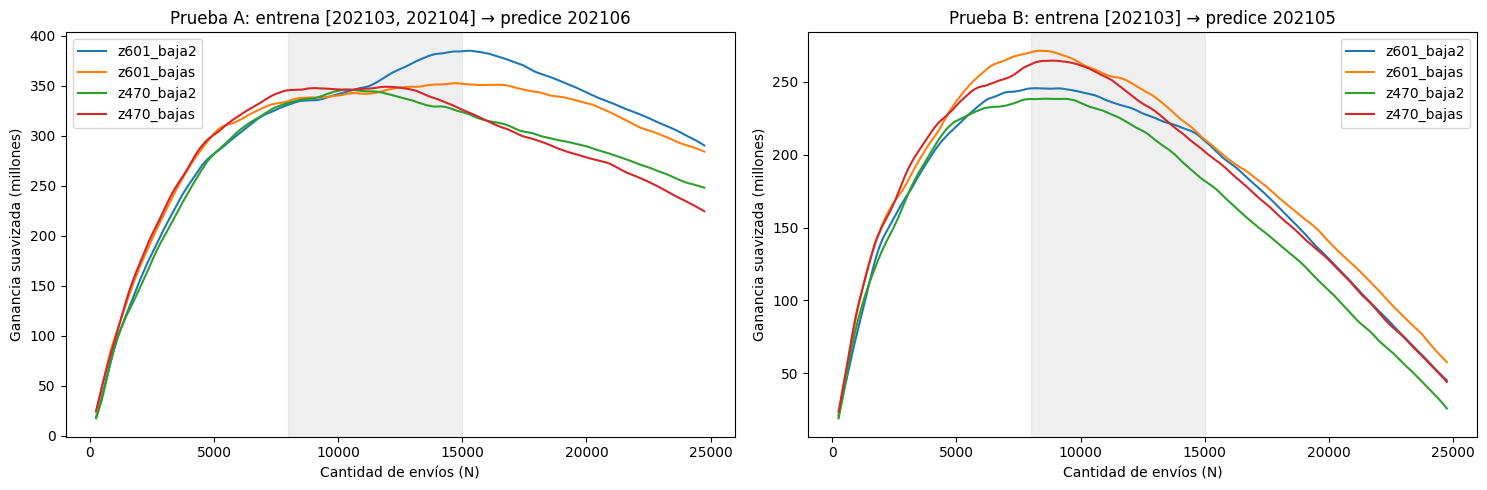

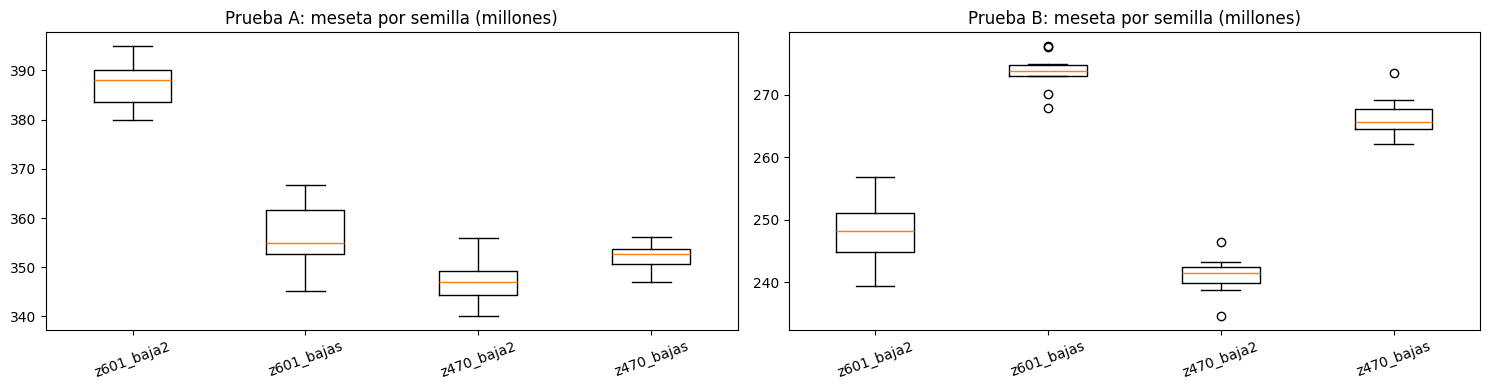

In [15]:
fig, ejes = plt.subplots(1, 2, figsize=(15, 5), sharey=False)
for eje, prueba in zip(ejes, PRUEBAS):
    for hiper, clase in product(HIPERPARAMETROS, CLASES):
        s = suavizar(promedios[(hiper, clase, prueba)])
        eje.plot(np.arange(1, len(s) + 1), s / 1e6, label=f'{hiper}_{clase}')
    eje.axvspan(min(CORTES), max(CORTES), color='grey', alpha=0.12)
    eje.set_title(f"Prueba {prueba}: entrena {PRUEBAS[prueba]['train']} → predice {PRUEBAS[prueba]['test']}")
    eje.set_xlabel('Cantidad de envíos (N)')
    eje.set_ylabel('Ganancia suavizada (millones)')
    eje.legend()
plt.tight_layout()
plt.show()

if len(SEMILLAS_A_USAR) > 1:
    fig, ejes = plt.subplots(1, 2, figsize=(15, 4))
    for eje, prueba in zip(ejes, PRUEBAS):
        datos, nombres = [], []
        for hiper, clase in product(HIPERPARAMETROS, CLASES):
            curvas, _ = cargar(hiper, clase, prueba, SEMILLAS_A_USAR)
            datos.append([meseta(c)[1] / 1e6 for c in curvas])
            nombres.append(f'{hiper}_{clase}')
        eje.boxplot(datos, tick_labels=nombres)
        eje.set_title(f'Prueba {prueba}: meseta por semilla (millones)')
        eje.tick_params(axis='x', rotation=20)
    plt.tight_layout()
    plt.show()

## 8. Elección (la decide el usuario)

**Criterio de la ficha:**
- gana la configuración que gana en A **y** en B;
- si cada prueba da un ganador distinto, gana la más estable (menor desvío);
- ante una diferencia chica, decide la estabilidad, no la media puntual.

La tabla de abajo muestra:
- la ganancia de cada configuración **relativa a la mejor** de cada prueba;
- el N sugerido para el primer submit: promedio de los N de A y B, redondeado a 500 y acotado a 8.000–15.000 (decisión 5).

**Pisos a superar** (CLAUDE.md §3):
- **B:** $123 M (reglas de la segmentación);
- **A:** $195 M (reglas) y $360,8 M (árbol de `z0607`).

Con `MODO_RAPIDO = True` es una sola semilla: **no sirve para decidir**, solo para medir tiempos.

In [16]:
eleccion = resumen.pivot(index='config', columns='prueba', values='ganancia_meseta')
eleccion = eleccion.join(resumen.pivot(index='config', columns='prueba', values='N_meseta').add_prefix('N_'))
for prueba in PRUEBAS:
    eleccion[f'vs_mejor_{prueba}_%'] = 100 * (eleccion[prueba] / eleccion[prueba].max() - 1)
eleccion['N_sugerido'] = (((eleccion['N_A'] + eleccion['N_B']) / 2 / 500).round() * 500).clip(8_000, 15_000).astype(int)
eleccion['supera_pisos'] = (eleccion['B'] > 123e6) & (eleccion['A'] > 360.8e6)
eleccion.sort_values('A', ascending=False).style.format(
    {'A': '{:,.0f}', 'B': '{:,.0f}', 'N_A': '{:,.0f}', 'N_B': '{:,.0f}',
     'vs_mejor_A_%': '{:+.1f}', 'vs_mejor_B_%': '{:+.1f}', 'N_sugerido': '{:,}'})

prueba,A,B,N_A,N_B,vs_mejor_A_%,vs_mejor_B_%,N_sugerido,supera_pisos
config,,,,,,,,
z601_baja2,"385,086,562","245,603,762","15,287","8,178",+0.0,-9.5,"11,500",True
z601_bajas,"352,613,782","271,311,652","14,714","8,359",-8.4,+0.0,"11,500",False
z470_bajas,"349,039,716","264,536,332","11,871","8,957",-9.4,-2.5,"10,500",False
z470_baja2,"346,207,929","238,408,643","10,345","8,512",-10.1,-12.1,"9,500",False


## 9. Cierre

- **Registro:** anotar en `decisiones.md` el **experimento #1** (tabla de A y B por configuración, con semillas) y la configuración elegida, con su N sugerido.
- **Lo que sigue:** `03_entrega.ipynb`, que entrena la configuración elegida con `202103`–`202106` y las 20 semillas, predice `202108` y genera los 20 CSV del primer submit.
- **Para el verificador:** fuga de información (variables, meses), ganancia con `BAJA+2` como único acierto, corte por N, semillas, hiperparámetros.